## Setup

In [1]:
import os
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
# หาไฟล์: โฟลเดอร์เดียวกับ notebook หรือ ../dataset/ (โครง repo ของทีม)
CANDIDATES = ['bank-additional-full.csv', '../dataset/bank-additional-full.csv']
CSV_PATH = next((p for p in CANDIDATES if os.path.exists(p)), CANDIDATES[0])

# ตรวจสอบและให้อัปโหลดหากยังไม่มีไฟล์
if not os.path.exists(CSV_PATH):
    from google.colab import files
    print("กรุณาอัปโหลดไฟล์:", CSV_PATH)
    files.upload()

print('โหลดข้อมูลจาก :', CSV_PATH)

# อ่านไฟล์เข้า DataFrame ได้ทันที เพราะ pd ถูก import ไว้ด้านบนแล้ว
df = pd.read_csv(CSV_PATH, sep=';')
print(df.shape)

pd.set_option('display.max_columns', None)
df.head()


โหลดข้อมูลจาก : bank-additional-full.csv
(41188, 21)


,age,job,marital,education,default,housing,loan,contact,month,day_of_week,duration,campaign,pdays,previous,poutcome,emp.var.rate,cons.price.idx,cons.conf.idx,euribor3m,nr.employed,y
0,56,housemaid,married,basic.4y,no,no,no,telephone,may,mon,261,1,999,0,nonexistent,1.1,93.994,-36.4,4.857,5191.0,no
1,57,services,married,high.school,unknown,no,no,telephone,may,mon,149,1,999,0,nonexistent,1.1,93.994,-36.4,4.857,5191.0,no
2,37,services,married,high.school,no,yes,no,telephone,may,mon,226,1,999,0,nonexistent,1.1,93.994,-36.4,4.857,5191.0,no
3,40,admin.,married,basic.6y,no,no,no,telephone,may,mon,151,1,999,0,nonexistent,1.1,93.994,-36.4,4.857,5191.0,no
4,56,services,married,high.school,no,no,yes,telephone,may,mon,307,1,999,0,nonexistent,1.1,93.994,-36.4,4.857,5191.0,no


## 1. Problem Statement

ธนาคารแห่งหนึ่งในโปรตุเกสทำแคมเปญโทรศัพท์ชวนลูกค้าเปิดบัญชีเงินฝากประจำ (term deposit) ช่วง พ.ค. 2008 ถึง พ.ย. 2010 รวม 41,188 สาย มีลูกค้าตอบตกลงเพียง 11.27%

ปัญหา: ฝ่ายขายโทรได้จำนวนจำกัด ถ้าโทรไล่ไปเรื่อยๆ เวลาส่วนใหญ่จะหมดไปกับคนที่ไม่สมัคร

เป้าหมาย: สร้างโมเดล classification ทำนายโอกาสที่ลูกค้าแต่ละคนจะสมัคร (y = yes) โดยใช้เฉพาะข้อมูลที่รู้ก่อนโทร แล้วใช้โอกาสนี้จัดลำดับว่าควรโทรหาใครก่อน

ข้อกำหนด: ตัด duration (ความยาวสาย) ออก เพราะรู้หลังวางสายแล้ว ไฟล์คำอธิบายของ dataset ระบุเองว่าควรตัดออกถ้าต้องการโมเดลที่ใช้งานได้จริง

การวัดผล: yes มีแค่ 11% โมเดลที่ทาย no ทุกคนก็ได้ accuracy 88.7% แล้ว จึงวัดด้วย ROC-AUC, precision, recall, F1 และดูว่าถ้าโทรเฉพาะ 20% แรกที่โมเดลจัดอันดับให้ จะเจอคนสมัครได้กี่เปอร์เซ็นต์ (ตัวเลข 20% เป็นสมมติฐาน)

ที่มาข้อมูล: Moro, S., Rita, P., & Cortez, P. (2014). Bank Marketing [Dataset]. UCI Machine Learning Repository. ไฟล์ bank-additional-full.csv

## 2. Basic Data Exploration for Target

,rows,percent
y,,
no,36548,88.73
yes,4640,11.27


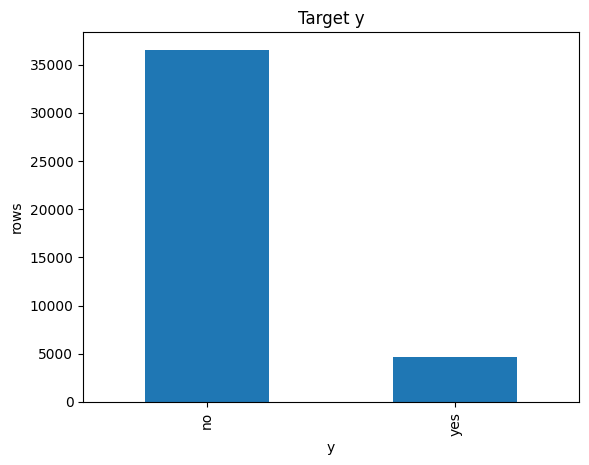

In [2]:
counts = df['y'].value_counts()
display(pd.DataFrame({'rows': counts, 'percent': (100 * counts / len(df)).round(2)}))
counts.plot(kind='bar')
plt.title('Target y')
plt.ylabel('rows')
plt.show()

**สรุปข้อ 2:**
- y = no 36,548 แถว (88.73%) และ yes 4,640 แถว (11.27%) ข้อมูลไม่สมดุล (imbalanced) ราว 7.9 : 1
- โมเดลที่ทาย no ทุกแถวได้ accuracy 88.73% ทั้งที่หาคนสมัครไม่เจอเลยสักคน จึงใช้ accuracy อย่างเดียววัดผลไม่ได้
- ตอนแบ่ง train/test ใช้ stratified ให้ทั้งสองชุดมีสัดส่วน yes เท่ากัน (ข้อ 14)
- อัตรา yes เปลี่ยนตามเวลามาก พ.ค. 2008 สมัคร 3.1% แต่ พ.ค. 2010 สมัคร 57.5% (ดูกราฟช่วงเวลาในข้อ 9)

## 3. Basic Data Exploration for Features

In [3]:
print('ขนาดข้อมูล:', df.shape, '| แถวซ้ำ:', df.duplicated().sum())
num_cols_all = df.select_dtypes('number').columns.tolist()
cat_cols_all = df.select_dtypes('object').columns.drop('y').tolist()
print('numeric', len(num_cols_all), ':', num_cols_all)
print('categorical', len(cat_cols_all), ':', cat_cols_all)
display(df[num_cols_all].describe().T.round(2))

ขนาดข้อมูล: (41188, 21) | แถวซ้ำ: 12
numeric 10 : ['age', 'duration', 'campaign', 'pdays', 'previous', 'emp.var.rate', 'cons.price.idx', 'cons.conf.idx', 'euribor3m', 'nr.employed']
categorical 10 : ['job', 'marital', 'education', 'default', 'housing', 'loan', 'contact', 'month', 'day_of_week', 'poutcome']


,count,mean,std,min,25%,50%,75%,max
age,41188.0,40.02,10.42,17.00,32.00,38.00,47.00,98.00
duration,41188.0,258.29,259.28,0.00,102.00,180.00,319.00,4918.00
campaign,41188.0,2.57,2.77,1.00,1.00,2.00,3.00,56.00
pdays,41188.0,962.48,186.91,0.00,999.00,999.00,999.00,999.00
previous,41188.0,0.17,0.49,0.00,0.00,0.00,0.00,7.00
emp.var.rate,41188.0,0.08,1.57,-3.40,-1.80,1.10,1.40,1.40
cons.price.idx,41188.0,93.58,0.58,92.20,93.08,93.75,93.99,94.77
cons.conf.idx,41188.0,-40.50,4.63,-50.80,-42.70,-41.80,-36.40,-26.90
euribor3m,41188.0,3.62,1.73,0.63,1.34,4.86,4.96,5.04
nr.employed,41188.0,5167.04,72.25,4963.60,5099.10,5191.00,5228.10,5228.10


**สรุปข้อ 3:** มี 20 feature แบ่งเป็น 4 กลุ่มตามไฟล์คำอธิบาย (bank-additional-names.txt)

| กลุ่ม | feature | ชนิด | ความหมาย |
|---|---|---|---|
| ข้อมูลลูกค้า | age | numeric | อายุ |
| | job | categorical | อาชีพ |
| | marital | categorical | สถานะสมรส (divorced รวมหม้าย) |
| | education | categorical | ระดับการศึกษา |
| | default | categorical | เคยผิดนัดชำระหนี้ไหม |
| | housing | categorical | มีสินเชื่อบ้านไหม |
| | loan | categorical | มีสินเชื่อส่วนตัวไหม |
| การติดต่อครั้งล่าสุด | contact | categorical | ช่องทาง (มือถือ / โทรศัพท์บ้าน) |
| | month | categorical | เดือนที่โทร |
| | day_of_week | categorical | วันที่โทร |
| | duration | numeric | ความยาวสาย (วินาที) รู้หลังวางสาย |
| ประวัติการติดต่อ | campaign | numeric | จำนวนครั้งที่โทรในแคมเปญนี้ รวมสายสุดท้าย |
| | pdays | numeric | กี่วันแล้วตั้งแต่ติดต่อในแคมเปญก่อน (999 = ไม่เคย) |
| | previous | numeric | เคยติดต่อก่อนแคมเปญนี้กี่ครั้ง |
| | poutcome | categorical | ผลของแคมเปญก่อน |
| เศรษฐกิจ (ระดับประเทศ) | emp.var.rate | numeric | อัตราการเปลี่ยนแปลงการจ้างงาน (รายไตรมาส) |
| | cons.price.idx | numeric | ดัชนีราคาผู้บริโภค (รายเดือน) |
| | cons.conf.idx | numeric | ดัชนีความเชื่อมั่นผู้บริโภค (รายเดือน) |
| | euribor3m | numeric | ดอกเบี้ยระหว่างธนาคาร 3 เดือน (รายวัน) |
| | nr.employed | numeric | จำนวนคนมีงานทำ (รายไตรมาส) |

- numeric 10 ตัว และ categorical 10 ตัว ไม่มีช่องว่าง (NaN) แต่ categorical 6 คอลัมน์มีค่า unknown ซึ่งไฟล์คำอธิบายบอกว่าคือ missing (ดูข้อ 5)
- แถวซ้ำ 12 แถว
- pdays ใช้ 999 แทน "ไม่เคยติดต่อ" ไม่ใช่ตัวเลขจริง
- ตัวแปรเศรษฐกิจ 5 ตัวเป็นค่าระดับประเทศจาก Banco de Portugal ไม่ใช่ข้อมูลของลูกค้าแต่ละคน
- หน้าเว็บ UCI แสดงตัวแปรของรุ่นเก่า (bank-full) ซึ่งไม่ตรงกับไฟล์ที่เราใช้ ให้อ้างจาก bank-additional-names.txt

## 4. Outlier Analysis

,min,Q1,median,Q3,max,unique,outlier_IQR,outlier_3SD,pct_IQR
feature,,,,,,,,,
age,17.000,32.000,38.000,47.000,98.000,78,469,369,1.14
campaign,1.000,1.000,2.000,3.000,56.000,42,2406,869,5.84
pdays,0.000,999.000,999.000,999.000,999.000,27,1515,1515,3.68
previous,0.000,0.000,0.000,0.000,7.000,8,5625,1064,13.66
emp.var.rate,-3.400,-1.800,1.100,1.400,1.400,10,0,0,0.00
cons.price.idx,92.201,93.075,93.749,93.994,94.767,26,0,0,0.00
cons.conf.idx,-50.800,-42.700,-41.800,-36.400,-26.900,26,447,0,1.09
euribor3m,0.634,1.344,4.857,4.961,5.045,316,0,0,0.00
nr.employed,4963.600,5099.100,5191.000,5228.100,5228.100,11,0,0,0.00


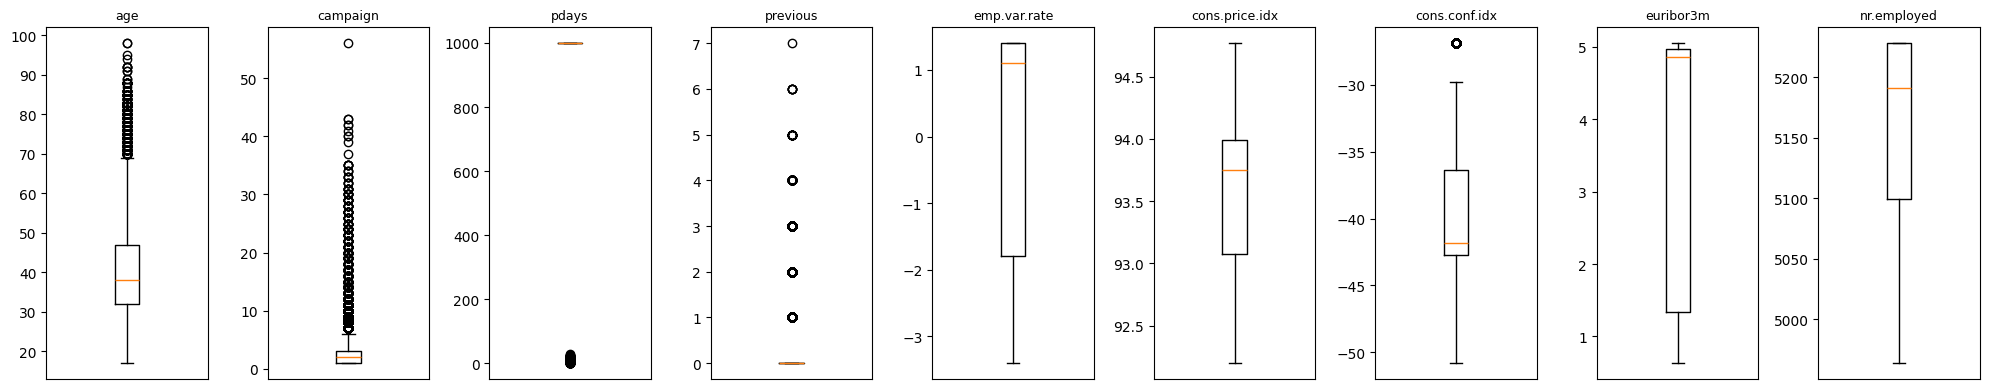

In [4]:
# ตรวจ outlier ของ continuous ทุกตัว ด้วย 2 กฎที่เรียนใน L3
#   IQR    : นอกหนวด boxplot  (ต่ำกว่า Q1 - 1.5*IQR หรือสูงกว่า Q3 + 1.5*IQR)
#   3 S.D. : ห่างจาก mean เกิน 3 เท่าของ S.D. (สมมติว่าข้อมูลเป็น Gaussian)
# duration ไม่ตรวจ เพราะตัดทิ้งแน่แล้ว (รู้หลังวางสาย = leakage)
num_cols = ['age', 'campaign', 'pdays', 'previous',
            'emp.var.rate', 'cons.price.idx', 'cons.conf.idx', 'euribor3m', 'nr.employed']

rows = []
for c in num_cols:
    x = df[c]
    q1, q3 = x.quantile([0.25, 0.75])
    iqr = q3 - q1
    n_iqr = ((x < q1 - 1.5 * iqr) | (x > q3 + 1.5 * iqr)).sum()
    n_3sd = ((x - x.mean()).abs() > 3 * x.std()).sum()
    rows.append({'feature': c, 'min': x.min(), 'Q1': q1, 'median': x.median(), 'Q3': q3,
                 'max': x.max(), 'unique': x.nunique(),
                 'outlier_IQR': n_iqr, 'outlier_3SD': n_3sd,
                 'pct_IQR': round(100 * n_iqr / len(x), 2)})
outlier_table = pd.DataFrame(rows).set_index('feature')
display(outlier_table)

fig, axes = plt.subplots(1, len(num_cols), figsize=(20, 4))
for ax, c in zip(axes, num_cols):
    ax.boxplot(df[c])
    ax.set_title(c, fontsize=9)
    ax.set_xticks([])
plt.tight_layout()
plt.show()

**สรุปข้อ 4:**
ตรวจ Outlier ด้วยกฎ IQR และ กฎ 3 เท่าของ S.D. สองกฎนี้ได้ผลไม่เท่ากัน เช่น campaign ได้ 2,406 กับ 869 แถวเพราะข้อมูลเบ้ ไม่ใช่รูประฆัง
- `age` (17-98) และ `campaign` (สูงสุด 56 ครั้ง) มีค่าที่เป็นจริง ไม่ใช่ข้อมูลที่ผิด จึงไม่ลบ
- `pdays` กับ `previous` ใช้กฎ IQR ไม่ได้เพราะค่าส่วนใหญ่เป็นค่าเดียวกัน (pdays = 999, previous = 0) Q1 กับ Q3 เลยเท่ากัน และ IQR = 0 ค่าที่ไม่ใช่ค่านี้เลยเป็น outlier ทั้งหมด ทั้งที่เป็นข้อมูลจริง ส่วน 999 เป็นรหัสแทน "ไม่เคยติดต่อ" ไม่ใช่ตัวเลข จะจัดในข้อ 5
- ตัวแปรเศรษฐกิจ 5 ตัวแปรเป็นค่าช่วง (รายเดือน/ไตรมาส) ทุกคนที่ถูกโทรในช่วงเดียวกันได้ค่าเดียวกัน จึงซ้ำกันเยอะ
- ไม่พบ outlier ที่เป็นข้อมูลผิด จึงไม่ได้ลบแถวไหน

## 5. Missing Values Analysis

In [5]:
# ค่าว่างมี 3 แบบ: (1) ช่องว่างจริง NaN  (2) คำว่า 'unknown'  (3) รหัส 999 ใน pdays

# (1) ช่องว่างจริง
print('ช่องว่างจริง (NaN) ทั้งไฟล์:', df.isna().sum().sum())

# (2) 'unknown' ในคอลัมน์ categorical
#     เทียบอัตราสมัคร (y = yes) ของกลุ่ม unknown กับกลุ่มที่รู้ค่า
#     ถ้าต่างกันมาก = unknown มีความหมายในตัวเอง ไม่ใช่แค่ข้อมูลหาย
cat_cols = df.select_dtypes('object').columns.drop('y')
rows = []
for c in cat_cols:
    is_unk = df[c] == 'unknown'
    if is_unk.sum() == 0:
        continue
    rows.append({'feature': c, 'n_unknown': is_unk.sum(),
                 'pct_unknown': round(100 * is_unk.mean(), 2),
                 'yes_rate_unknown': round(100 * (df.loc[is_unk, 'y'] == 'yes').mean(), 1),
                 'yes_rate_known': round(100 * (df.loc[~is_unk, 'y'] == 'yes').mean(), 1)})
display(pd.DataFrame(rows).set_index('feature').sort_values('pct_unknown', ascending=False))

print(df['default'].value_counts(), '\n')

# (3) pdays = 999 ไฟล์ names บอกว่าแปลว่า "ไม่เคยถูกติดต่อมาก่อน"
#     เช็คกับอีก 2 คอลัมน์ที่บอกเรื่องเดียวกัน: previous (เคยติดต่อกี่ครั้ง), poutcome (ผลแคมเปญก่อน)
display(pd.crosstab(df['pdays'] == 999, df['poutcome'],
                    rownames=['pdays == 999'], margins=True))

ช่องว่างจริง (NaN) ทั้งไฟล์: 0


,n_unknown,pct_unknown,yes_rate_unknown,yes_rate_known
feature,,,,
default,8597,20.87,5.2,12.9
education,1731,4.20,14.5,11.1
housing,990,2.40,10.8,11.3
loan,990,2.40,10.8,11.3
job,330,0.80,11.2,11.3
marital,80,0.19,15.0,11.3


default
no         32588
unknown     8597
yes            3
Name: count, dtype: int64 



poutcome,failure,nonexistent,success,All
pdays == 999,,,,
False,142,0,1373,1515
True,4110,35563,0,39673
All,4252,35563,1373,41188


**สรุปข้อ 5:** 
- ช่องว่าง (NaN) มี 0 ช่อง
- unknown มีความหมายของมัน เช่น `default` กลุ่ม unknown สมัคร 5.2% แต่กลุ่มที่รู้ค่าสมัคร 12.9% เราเลยเก็บ unknown ไว้เป็นหมวดหนึ่ง ไม่เติมค่า
- pdays = 999 ควรแปลว่าไม่เคยถูกติดต่อ แต่มี 4,110 แถวที่ poutcome เป็น failure คือเคยถูกติดต่อแล้วแต่ไม่สมัคร และไม่มีข้อมูลว่าติดต่อไปเมื่อกี่วันก่อน 999 เลยมีสองความหมาย จึงใช้ pdays เป็นตัวเลขตรงๆ ไม่ได้

## 6. Feature Selection by Visualization (Continuous Features)

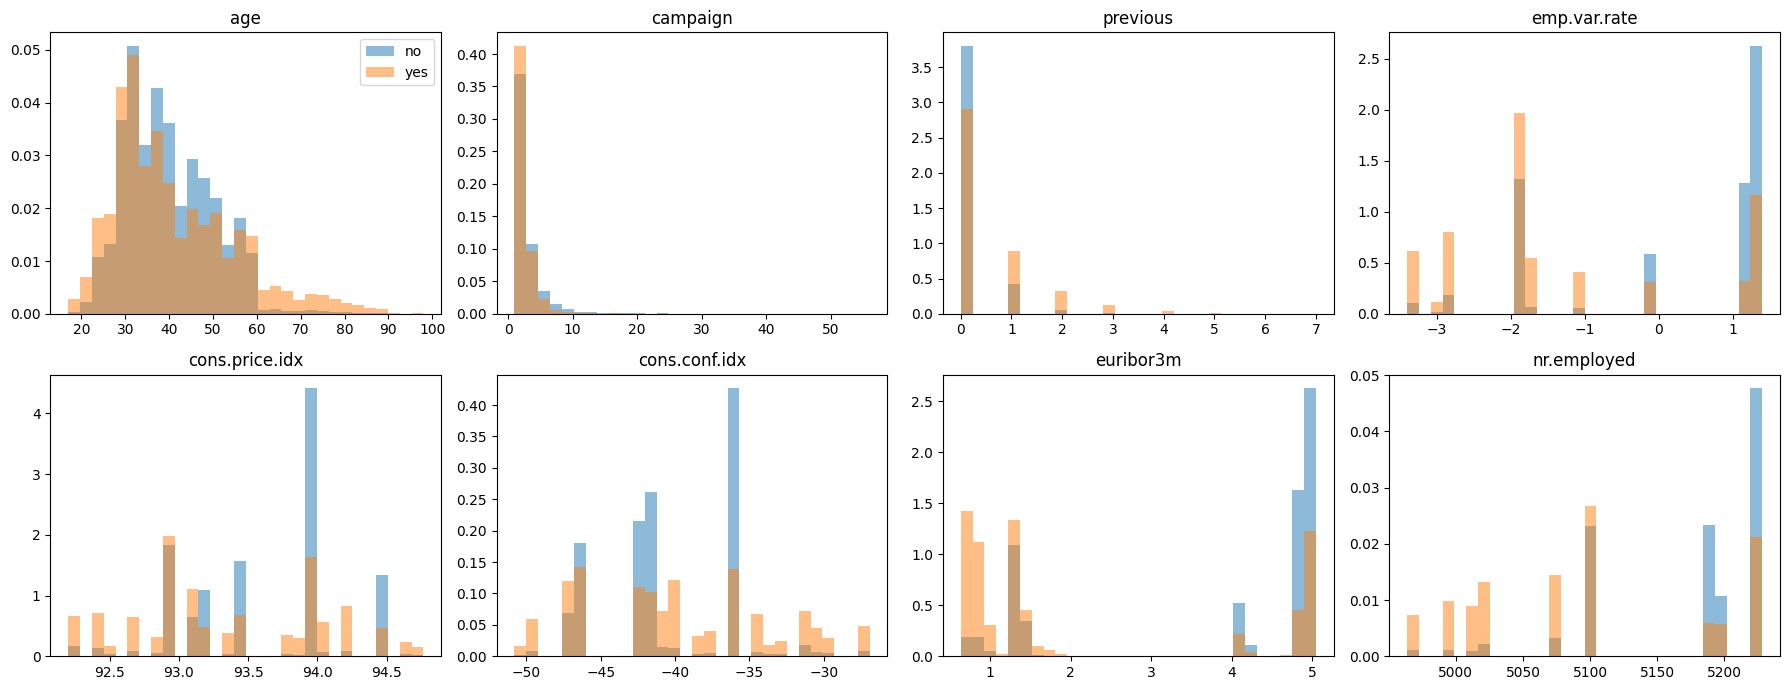

y,no,yes
age,38.000,37.000
campaign,2.000,2.000
previous,0.000,0.000
emp.var.rate,1.100,-1.800
cons.price.idx,93.918,93.200
cons.conf.idx,-41.800,-40.400
euribor3m,4.857,1.266
nr.employed,5195.800,5099.100


In [6]:
# ดูด้วยตาว่า continuous ตัวไหนแยกคนสมัคร (yes) กับไม่สมัคร (no) ได้
# วาด histogram สองกลุ่มทับกัน, density=True ให้สองกลุ่มสูงเทียบกันได้ (yes มีแค่ 11%)
#   สองสีทับกันสนิท = แยกไม่ได้, สองสีเยื้องกัน = มีประโยชน์
# pdays ไม่วาด เพราะ 96% เป็นรหัส 999 (ข้อ 5) กราฟจะเหลือแท่งเดียว
plot_cols = ['age', 'campaign', 'previous',
             'emp.var.rate', 'cons.price.idx', 'cons.conf.idx', 'euribor3m', 'nr.employed']
is_yes = df['y'] == 'yes'

fig, axes = plt.subplots(2, 4, figsize=(18, 7))
for ax, c in zip(axes.flat, plot_cols):
    bins = np.histogram_bin_edges(df[c], bins=30)
    ax.hist(df.loc[~is_yes, c], bins=bins, density=True, alpha=0.5, label='no')
    ax.hist(df.loc[is_yes, c], bins=bins, density=True, alpha=0.5, label='yes')
    ax.set_title(c)
axes.flat[0].legend()
plt.tight_layout()
plt.show()

# median ของสองกลุ่ม ไว้ยืนยันสิ่งที่เห็นในกราฟ
display(df.groupby('y')[plot_cols].median().T)

**สรุปข้อ 6:**
- แยกชัด (สองสีเยื้องกันมาก): euribor3m สีส้มกองที่ดอกเบี้ยต่ำ สีฟ้ากองที่ดอกเบี้ยสูง median ต่างกันมาก (1.27 กับ 4.86), emp.var.rate กับ nr.employed เป็นแบบเดียวกัน
- แยกได้บางช่วง: age ช่วงกลางทับกัน แต่อายุน้อยกว่า 25 กับมากกว่า 60 สมัครมากกว่า (median ต่างกันแค่ 1 ปี แต่กราฟเห็นที่ปลาย) · previous ค่า 1–3 สมัครมากกว่า, cons.price.idx กับ cons.conf.idx เยื้องแค่บางค่า
- แทบแยกไม่ได้ (สองสีทับกันสนิท): campaign


## 7. Feature Selection by Statistical Analysis (Continuous Features)

In [7]:
from sklearn.feature_selection import f_classif

# ANOVA F-test: F = ความต่างของค่าเฉลี่ยระหว่างกลุ่ม yes/no ÷ การกระจายภายในกลุ่ม
#   F สูง = แยกสองกลุ่มได้ดี · p-value < 0.05 = ความต่างไม่น่าเกิดจากความบังเอิญ
# ข้อมูล 41,188 แถว p-value จะเล็กเกือบทุกตัว ⇒ ใช้ F จัดอันดับ
F, p = f_classif(df[plot_cols], is_yes)
anova_table = pd.DataFrame({'F': F.round(1), 'p_value': p}, index=plot_cols)
anova_table = anova_table.sort_values('F', ascending=False)
display(anova_table)

# mean ของสองกลุ่ม (ANOVA เทียบ mean ไม่ใช่ median)
display(df.groupby('y')[plot_cols].mean().T.round(2))

,F,p_value
nr.employed,5926.6,0.000000e+00
euribor3m,4309.5,0.000000e+00
emp.var.rate,4023.8,0.000000e+00
previous,2304.3,0.000000e+00
cons.price.idx,778.6,9.318923e-170
campaign,182.2,2.007780e-41
cons.conf.idx,124.4,7.536665e-29
age,38.1,6.802136e-10


y,no,yes
age,39.91,40.91
campaign,2.63,2.05
previous,0.13,0.49
emp.var.rate,0.25,-1.23
cons.price.idx,93.60,93.35
cons.conf.idx,-40.59,-39.79
euribor3m,3.81,2.12
nr.employed,5176.17,5095.12


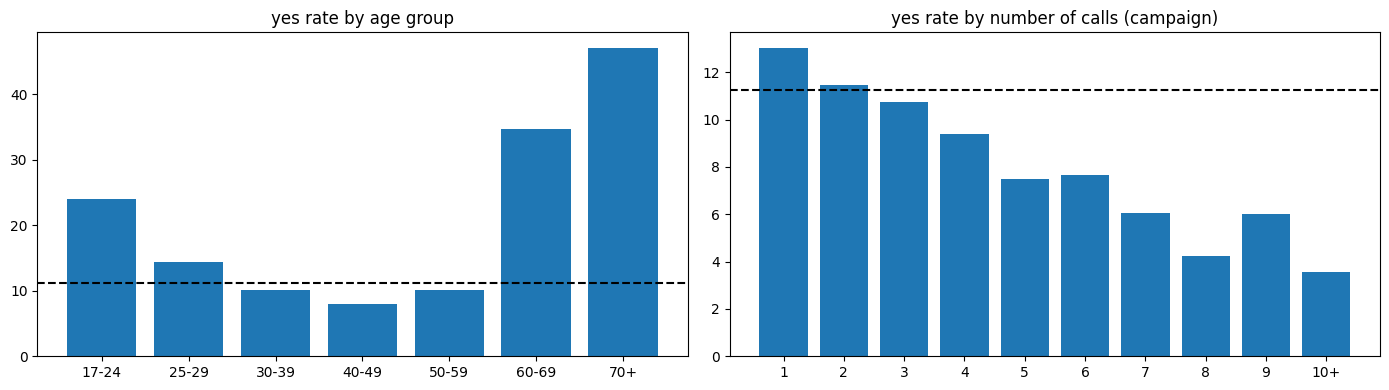

In [8]:
# ภาพที่ตาราง F มองไม่เห็น: อัตราสมัครแยกตามช่วงอายุ และตามจำนวนครั้งที่โทร
age_group = pd.cut(df['age'], bins=[16, 24, 29, 39, 49, 59, 69, 100],
                   labels=['17-24', '25-29', '30-39', '40-49', '50-59', '60-69', '70+'])
calls = df['campaign'].clip(upper=10).astype(str).replace('10', '10+')
calls = pd.Categorical(calls, categories=[str(i) for i in range(1, 10)] + ['10+'], ordered=True)

fig, (a1, a2) = plt.subplots(1, 2, figsize=(14, 4))
for ax, groups, title in [(a1, age_group, 'yes rate by age group'),
                          (a2, calls, 'yes rate by number of calls (campaign)')]:
    rate = is_yes.groupby(groups, observed=True).mean() * 100
    ax.bar(rate.index.astype(str), rate.values)
    ax.axhline(is_yes.mean() * 100, color='k', ls='--')
    ax.set_title(title)
plt.tight_layout()
plt.show()


**สรุปข้อ 7:**
- F สูงสุด 3 อันดับแรก: nr.employed(5926.6), euribor3m(4309.5), emp.var.rate(4023.8) ตรงกับช่อง "แยกชัด" ในข้อ 6 ทั้งสามตัว สองวิธีให้ผลตรงกัน เลยมั่นใจได้มากขึ้น
- p-value: น้อยกว่า 0.05 ทุกตัว ตัวที่มากสุดคือ `age` มีค่า 0.00000000068 (6.8e-10) เลยใช้ p-value คัดตัวออกไม่ได้
- age ได้ F ต่ำสุด (38.1) แต่กราฟใต้ตารางเป็นรูปตัว U: อายุ 17-24 สมัคร 24.0%, 40-49 สมัคร 7.9%, 60-69 สมัคร 34.7%, 70+ สมัคร 47.1% F ดูแค่ค่าเฉลี่ยของสองกลุ่ม จึงมองไม่เห็นรูปนี้
- campaign: โทรครั้งเดียวสมัคร 13.0% โทร 10 ครั้งขึ้นไปเหลือ 3.6% ยิ่งโทรซ้ำยิ่งสมัครน้อย

## 8. Feature Selection Summary (Continuous Features)

| feature | ข้อ 6 (กราฟ) | ข้อ 7 (F) | เก็บ / ตัด | เหตุผล |
|---|---|---|---|---|
| nr.employed | แยกชัด | 5926.6 | เก็บ | สองวิธีตรงกัน, เป็นตัวแทนช่วงเวลา |
| euribor3m | แยกชัด | 4309.5 | เก็บ | สองวิธีตรงกัน, เป็นตัวแทนช่วงเวลา |
| emp.var.rate | แยกชัด | 4023.8 | เก็บ | สองวิธีตรงกัน, เป็นตัวแทนช่วงเวลา |
| previous | บางช่วง (ค่า 1–3) | 2304.3 | เก็บ | เคยถูกติดต่อแล้วสมัครมากกว่า |
| cons.price.idx | บางช่วง | 778.6 | เก็บ | มีผลทั้งสองวิธี |
| cons.conf.idx | บางช่วง | 124.4 | เก็บ | มีผลทั้งสองวิธี |
| age | บางช่วง (ปลายสองข้าง) | 38.1 | เก็บ | F ต่ำเพราะปลายสองข้างหักล้างกัน แต่กราฟเห็นผล |
| campaign | แทบแยกไม่ได้ | 182.2 | รอตกลงกับทีม | นับรวมสายสุดท้าย |
| pdays | ไม่ได้วาด (999) | ไม่ได้ทดสอบ | รอตกลงกับทีม | 999 มีสองความหมาย |
| duration | ไม่ได้วาด | ไม่ได้ทดสอบ | ตัด | รู้หลังวางสาย (leakage) |

หมายเหตุ: ตัวแปรเศรษฐกิจ 5 ตัวอาจซ้ำกันเอง จะเช็คในข้อ 12 และอาจตัดบางตัว

## 9. Feature Selection by Visualization (Categorical Features)

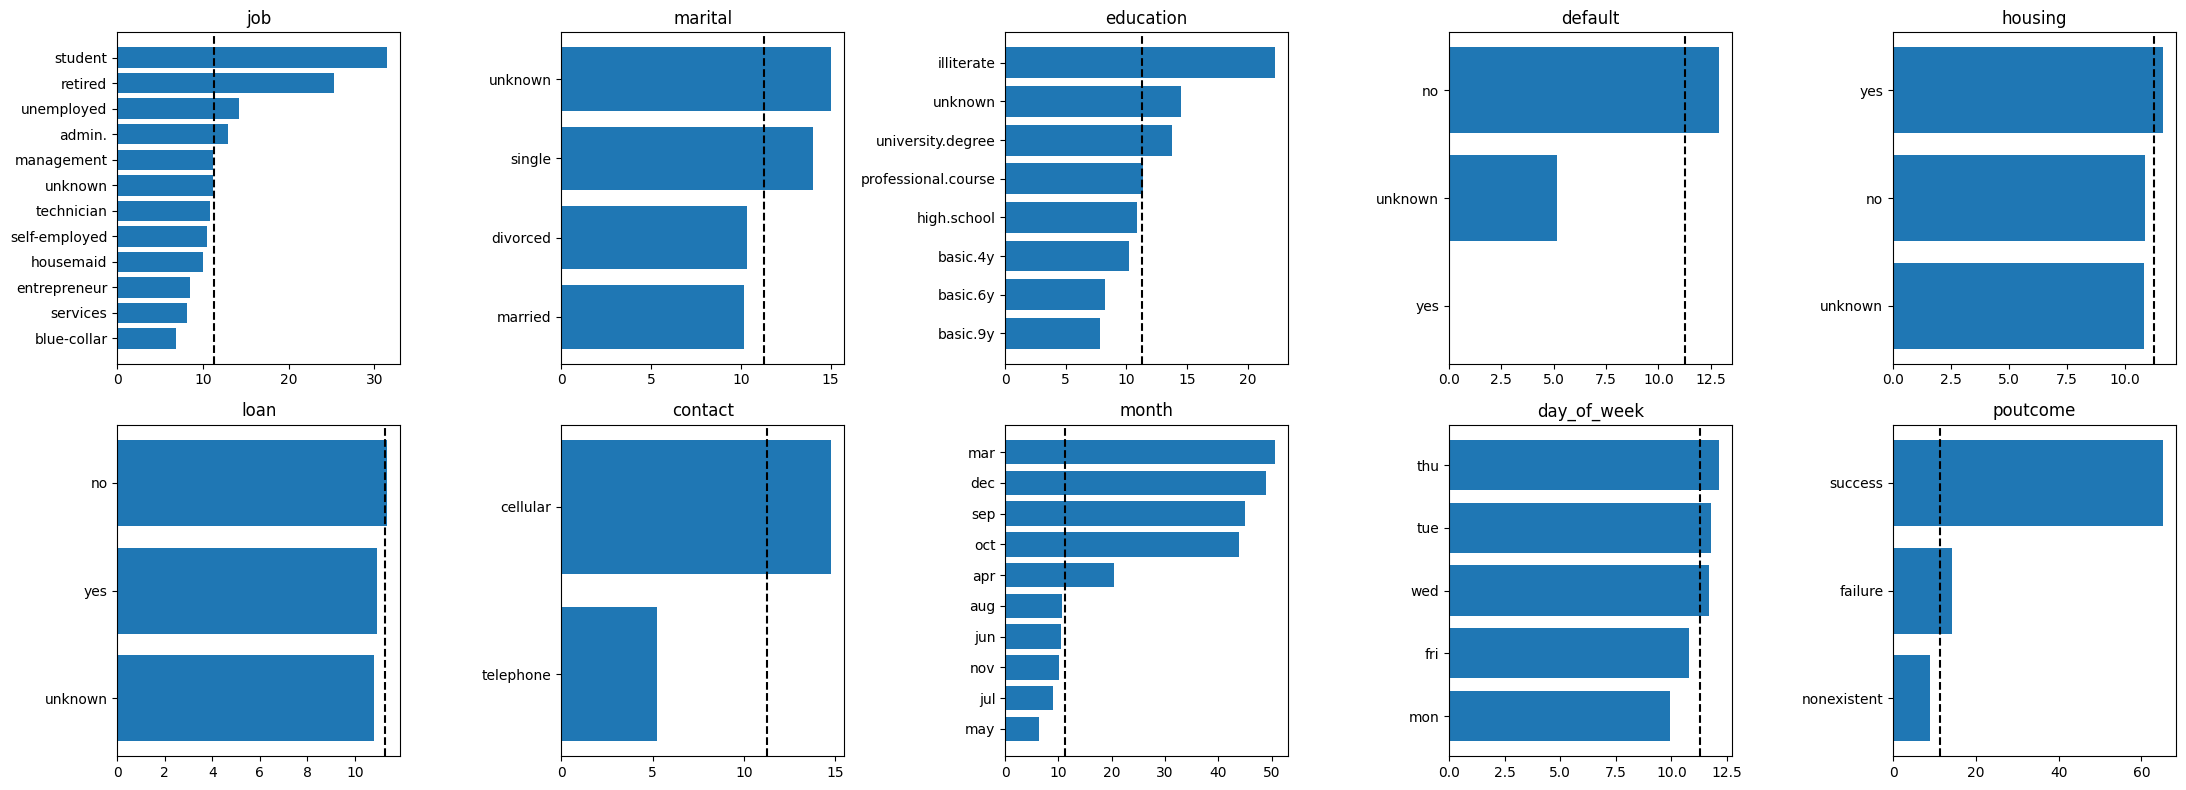

In [9]:
# อัตราสมัคร (%) ของแต่ละหมวด, เส้นประ = อัตราเฉลี่ยทั้งไฟล์ (11.3%)
#   แท่งยาว/สั้นกว่าเส้นประมาก = หมวดนั้นต่างจากคนทั่วไป = feature มีประโยชน์
#   ทุกแท่งยาวพอๆ กับเส้นประ = feature แทบไม่ช่วย
cat_cols = ['job', 'marital', 'education', 'default', 'housing', 'loan',
            'contact', 'month', 'day_of_week', 'poutcome']
overall = is_yes.mean() * 100

fig, axes = plt.subplots(2, 5, figsize=(22, 8))
for ax, c in zip(axes.flat, cat_cols):
    rate = df.groupby(c)['y'].apply(lambda s: (s == 'yes').mean() * 100).sort_values()
    ax.barh(rate.index, rate.values)
    ax.axvline(overall, color='k', ls='--')
    ax.set_title(c)
plt.tight_layout()
plt.show()

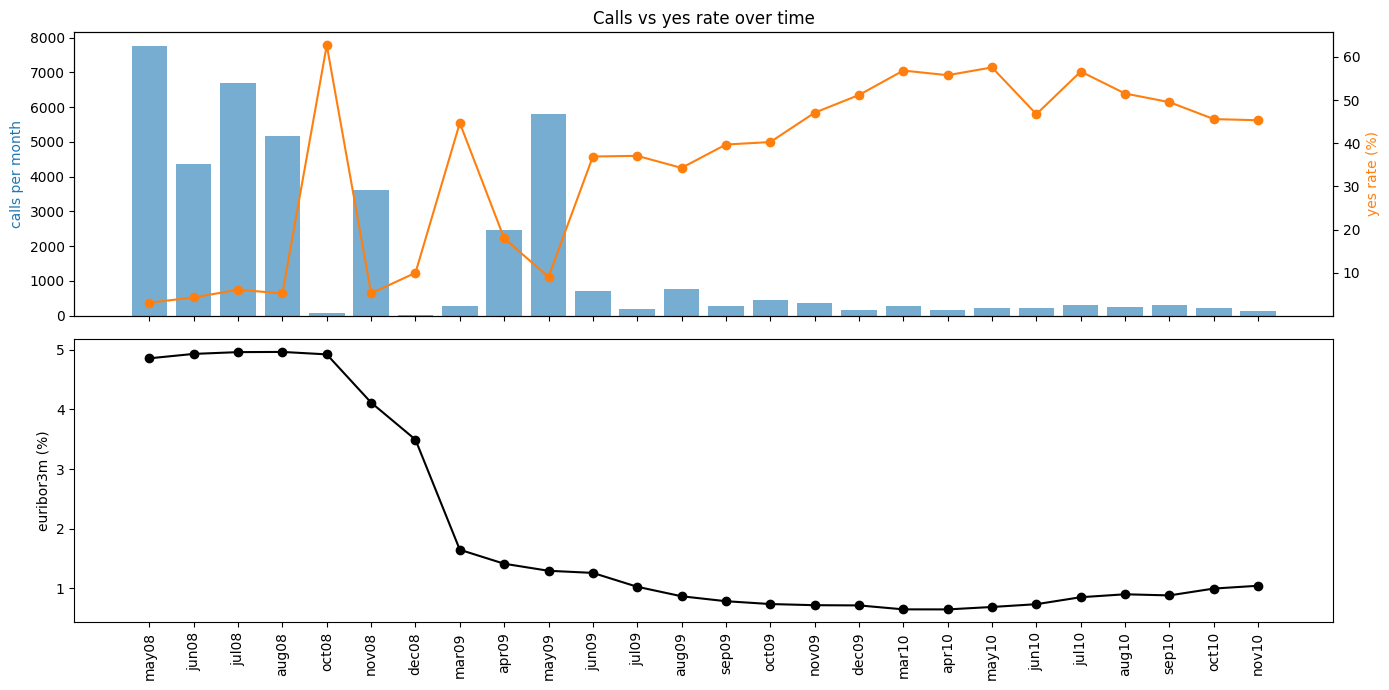

,label,calls,yes_rate,euribor
period,,,,
1,may08,7763,0.030916,4.857663
2,jun08,4374,0.042981,4.931639
3,jul08,6685,0.060883,4.961587
4,aug08,5175,0.052367,4.964804
5,oct08,67,0.626866,4.923776
6,nov08,3616,0.052544,4.114895
7,dec08,10,0.100000,3.493400
8,mar09,282,0.446809,1.646220
9,apr09,2458,0.179821,1.411722


In [10]:
# month หลอกตาไหม? เรียงข้อมูลตามเวลาจริง (ไฟล์เรียงตามวันที่ พ.ค. 2008 – พ.ย. 2010 แต่ไม่มีคอลัมน์ปี)
# เดือนเปลี่ยน = ขึ้นเดือนใหม่ · เดือนย้อนกลับ (เช่น dec → mar) = ขึ้นปีใหม่
order = ['jan', 'feb', 'mar', 'apr', 'may', 'jun', 'jul', 'aug', 'sep', 'oct', 'nov', 'dec']
m = df['month'].map(order.index)
period = (df['month'] != df['month'].shift()).cumsum()
year = 2008 + (m.diff() < 0).cumsum()
label = df['month'] + (year % 100).astype(str).str.zfill(2)

by_time = (pd.DataFrame({'period': period, 'label': label, 'yes': is_yes, 'euribor': df['euribor3m']})
           .groupby('period')
           .agg(label=('label', 'first'), calls=('yes', 'size'),
                yes_rate=('yes', 'mean'), euribor=('euribor', 'mean')))

fig, (ax1, ax3) = plt.subplots(2, 1, figsize=(14, 7), sharex=True)
x = np.arange(len(by_time))
ax1.bar(x, by_time['calls'], color='tab:blue', alpha=0.6)
ax1.set_ylabel('calls per month', color='tab:blue')
ax2 = ax1.twinx()
ax2.plot(x, by_time['yes_rate'] * 100, color='tab:orange', marker='o')
ax2.set_ylabel('yes rate (%)', color='tab:orange')
ax1.set_title('Calls vs yes rate over time')
ax3.plot(x, by_time['euribor'], color='k', marker='o')
ax3.set_ylabel('euribor3m (%)')
ax3.set_xticks(x)
ax3.set_xticklabels(by_time['label'], rotation=90)
plt.tight_layout()
plt.show()
display(by_time)

**สรุปข้อ 9:**
- แยกชัด: poutcome(success สมัคร ~65% เทียบกับค่าเฉลี่ย 11.3%), contact(มือถือ ~15% โทรศัพท์บ้าน ~5%), month (mar/dec/sep/oct สูง 45–50% แต่เป็นเดือนที่โทรน้อย เมื่อเรียงตามเวลาจริงแล้ว month เป็นตัวแทนช่วงเวลา ดูกราฟด้านบน)
- แยกได้บางหมวด: job (student กับ retired สมัครสูง), default (unknown สมัครต่ำ), education, marital
- แทบแยกไม่ได้: housing, loan, day_of_week (ทุกแท่งใกล้เส้นประ)

## 10. Feature Selection by Statistical Analysis (Categorical Features)

In [11]:
from scipy.stats import chi2_contingency

# chi-square test: feature กับ y เป็นอิสระต่อกันไหม (L3)
#   p-value < 0.05 = ไม่อิสระ = feature สัมพันธ์กับการสมัคร
# ข้อมูลเยอะ p-value จะเล็กเกือบทุกตัว (เหมือนข้อ 7) ⇒ ใช้ค่า chi2 จัดอันดับแทน
#   chi2 สูง = ตารางจริงต่างจากตารางที่ควรเป็นถ้า feature ไม่เกี่ยวกับ y มาก = สัมพันธ์แรง
#   ทำหน้าที่เหมือน F ในข้อ 7 แต่ใช้กับ categorical (ทุกตัวใช้ข้อมูล 41,188 แถวเท่ากัน จึงเทียบกันได้)
rows = []
for c in cat_cols:
    table = pd.crosstab(df[c], df['y'])
    chi2, p, dof, _ = chi2_contingency(table)
    rows.append({'feature': c, 'n_categories': df[c].nunique(),
                 'chi2': round(chi2, 1), 'p_value': p})
chi_table = pd.DataFrame(rows).set_index('feature').sort_values('chi2', ascending=False)
display(chi_table)

,n_categories,chi2,p_value
feature,,,
poutcome,3,4230.5,0.000000e+00
month,10,3101.1,0.000000e+00
job,12,961.2,4.189763e-199
contact,2,862.3,1.525986e-189
default,3,406.6,5.161958e-89
education,8,193.1,3.305189e-38
marital,4,122.7,2.068015e-26
day_of_week,5,26.1,2.958482e-05
housing,3,5.7,5.829448e-02


**สรุปข้อ 10:**
- p < 0.05 ทุกตัว ยกเว้น housing (p = 0.058) และ loan (p = 0.579) สองตัวนี้ไม่ผ่านทั้งที่ข้อมูลมี 41,188 แถว จึงไม่สัมพันธ์กับการสมัคร
- chi2 สูงสุดคือ poutcome (4,230.5) และ month (3,101.1) ตรงกับข้อ 9 ที่สองตัวนี้แยกชัด
- day_of_week ผ่าน (p = 0.00003) แต่ chi2 แค่ 26.1 ต่ำกว่า poutcome ราว 160 เท่า ผ่านเพราะข้อมูลเยอะ ไม่ใช่เพราะสัมพันธ์แรง

## 11. Feature Selection Summary (Categorical Features)

| feature | ข้อ 9 (กราฟ) | ข้อ 10 (chi²) | p < 0.05 | เก็บ / ตัด | เหตุผล |
|---|---|---|---|---|---|
| poutcome | แยกชัด (success สมัคร ~65%) | 4,230.5 | ผ่าน | เก็บ | แยกชัดที่สุด |
| month | แยกชัด แต่หลอกตา | 3,101.1 | ผ่าน | เก็บ | เป็นตัวแทนช่วงเวลา เหมือนตัวแปรเศรษฐกิจ |
| job | บางหมวด (student, retired) | 961.2 | ผ่าน | เก็บ | |
| contact | แยกชัด (มือถือ 15% / โทรศัพท์บ้าน 5%) | 862.3 | ผ่าน | เก็บ | |
| default | บางหมวด (unknown ต่ำ) | 406.6 | ผ่าน | เก็บ | ผลมาจาก unknown กับ no (yes มีแค่ 3 แถว) |
| education | บางหมวด | 193.1 | ผ่าน | เก็บ | |
| marital | บางหมวด | 122.7 | ผ่าน | เก็บ | อ่อน |
| day_of_week | แทบแยกไม่ได้ | 26.1 | ผ่าน | ตัด (เสนอ) | p ผ่านเพราะข้อมูลเยอะ แต่ chi² ต่ำมาก |
| housing | แทบแยกไม่ได้ | 5.7 | ไม่ผ่าน (0.058) | ตัด | ไม่ผ่านทั้งที่ข้อมูลเยอะ |
| loan | แทบแยกไม่ได้ | 1.1 | ไม่ผ่าน (0.579) | ตัด | ไม่ผ่านทั้งที่ข้อมูลเยอะ |

## 12. Redundant Features Analysis

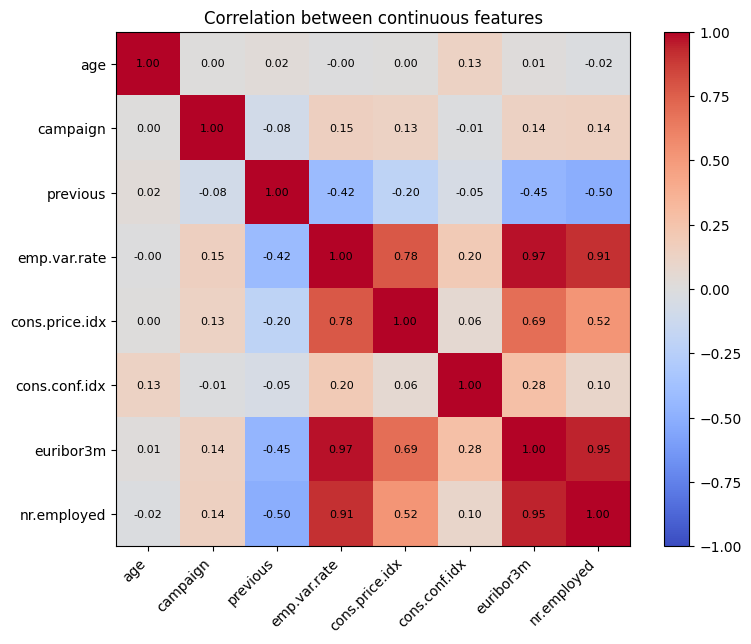

loan unknown,False,True
housing unknown,,
False,40198,0
True,0,990


In [12]:
# (1) continuous: ตัวไหนซ้ำกันเอง? ดู correlation ทีละคู่ (-1 ถึง 1)
#     |corr| ≥ 0.9 = แทบเป็นข้อมูลเดียวกัน เก็บไว้ตัวเดียวพอ
corr = df[plot_cols].corr()
fig, ax = plt.subplots(figsize=(8, 6.5))
im = ax.imshow(corr, cmap='coolwarm', vmin=-1, vmax=1)
ax.set_xticks(range(len(plot_cols)))
ax.set_xticklabels(plot_cols, rotation=45, ha='right')
ax.set_yticks(range(len(plot_cols)))
ax.set_yticklabels(plot_cols)
for i in range(len(plot_cols)):
    for j in range(len(plot_cols)):
        ax.text(j, i, f'{corr.iloc[i, j]:.2f}', ha='center', va='center', fontsize=8)
fig.colorbar(im)
ax.set_title('Correlation between continuous features')
plt.tight_layout()
plt.show()

# (2) housing กับ loan: unknown 990 แถวเท่ากัน เป็นแถวเดียวกันไหม
display(pd.crosstab(df['housing'] == 'unknown', df['loan'] == 'unknown',
                    rownames=['housing unknown'], colnames=['loan unknown']))

**สรุปข้อ 12:**
- euribor3m, emp.var.rate, nr.employed ซ้ำกันเอง (corr 0.91–0.97) = แทบเป็นข้อมูลเดียวกัน เก็บไว้ตัวเดียวพอ เสนอ nr.employed เพราะ F สูงสุดในข้อ 7
- cons.price.idx (0.78 กับ emp.var.rate) และ cons.conf.idx (≤ 0.28) ไม่ถึง 0.9 เก็บไว้
- housing กับ loan ที่เป็น unknown คือ 990 แถวเดียวกันทุกแถว (ไม่ตอบทั้งสองคำถาม) แต่ทั้งคู่ถูกตัดอยู่แล้วในข้อ 11
- pdays ซ้ำกับ poutcome (ข้อ 5: pdays จริง 1,515 แถว เป็น success 1,373) เสนอตัด pdays
- เหตุผลที่ต้องตัดตัวที่ซ้ำ: ถ้าใส่ทั้งสามตัว Logistic Regression จะแบ่งน้ำหนักให้สามตัวแบบไม่นิ่ง อ่านค่าสัมประสิทธิ์ไม่ได้ (Decision Tree ไม่ค่อยมีปัญหา) จะเทียบผลตัด/ไม่ตัดในข้อ 15


## 13. Feature Extraction

In [13]:
# สร้าง feature ใหม่จากของเดิม (ทำบนสำเนา df_fe ไม่แก้ df ต้นฉบับ)
df_fe = df.copy()

# (1) age_group: age เป็นรูปตัว U (กราฟใต้ข้อ 7)
#     Logistic Regression ใช้ age เป็นเส้นตรง จับตัว U ไม่ได้, แบ่งช่วงแล้วแต่ละช่วงได้น้ำหนักของตัวเอง
df_fe['age_group'] = pd.cut(df_fe['age'], bins=[16, 24, 60, 100], labels=['<25', '25-60', '>60'])

# (2) previous_group: 86% เป็น 0 และค่า 4-7 มีน้อยมาก → รวมเป็น 0 / 1 / 2+
df_fe['previous_group'] = pd.cut(df_fe['previous'], bins=[-1, 0, 1, 10], labels=['0', '1', '2+'])

# อัตราสมัครของแต่ละกลุ่มใหม่ (หลักฐานว่ากลุ่มที่แบ่งต่างกันจริง)
for c in ['age_group', 'previous_group']:
    display(df_fe.groupby(c, observed=True)['y']
            .agg(rows='size', yes_rate=lambda s: round((s == 'yes').mean() * 100, 1)))

,rows,yes_rate
age_group,,
<25,1068,24.0
25-60,39210,10.1
>60,910,45.5


,rows,yes_rate
previous_group,,
0,35563,8.8
1,4561,21.2
2+,1064,50.0


**สรุปข้อ 13:**
- age_group (<25 / 25-60 / >60): สมัคร 24.0% / 10.1% / 45.5% เพราะ age เป็นรูปตัว U ถ้าใช้ age ตรงๆ Logistic Regression จะลากเส้นตรงแล้วจับปลายสองข้างไม่ได้ แบ่งช่วงแล้วแต่ละช่วงได้น้ำหนักของตัวเอง
- previous_group (0 / 1 / 2+): สมัคร 8.8% / 21.2% / 50.0% ยิ่งเคยถูกติดต่อมาก ยิ่งสมัครมาก และรวมค่า 4-7 ที่มีน้อยเข้าด้วยกัน
- จะเทียบในข้อ 15 ว่าใช้ feature ใหม่แล้วโมเดลดีขึ้นไหม

## 14. Data Preprocessing

> **แผน (ร่างให้ทีมเลือก ยังไม่ได้ทำ)**

| เรื่อง | ร่าง | เหตุผล |
|---|---|---|
| เก็บ   | euribor3m, cons.price.idx, cons.conf.idx |   |
| ตัดออก | duration + ที่ทีมตกลง | |
| categorical | one-hot โดยให้ unknown เป็นคอลัมน์ของตัวเอง | ข้อ 5: unknown มีความหมาย |
| continuous | StandardScaler โดย fit กับ train เท่านั้น | ถ้า fit ก่อนแบ่งข้อมูล ข้อมูล test จะรั่วเข้า train |
| แบ่งข้อมูล | stratified 80/20 | yes มีแค่ 11% ต้องให้ train กับ test มีสัดส่วนเท่ากัน |
| ลำดับแถว | ห้ามสลับลำดับในไฟล์ต้นฉบับ | ลำดับแถวคือข้อมูลเวลาอย่างเดียวที่มี เผื่อทำแนว D |
| age | ลองทั้ง age และ age_group | ให้ข้อ 15 เป็นตัวตัดสิน |